# Lab04 - FFT oraz 2D DWT w rozpoznawaniu obrazów

### 1) wczytanie emoji

In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt

script_dir = globals()['_dh'][0]

In [2]:
def load_emojis(folder_name="emojis"):
    folder_path = os.path.join(script_dir, folder_name)
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Nie znaleziono folderu z emoji: {folder_path}")

    emojis = {}
    for filename in sorted(os.listdir(folder_path)):
        if filename.lower().endswith(".png"):
            emoji_name = os.path.splitext(filename)[0]
            emoji_path = os.path.join(folder_path, filename)
            emoji_image = cv2.imread(emoji_path, cv2.IMREAD_UNCHANGED)
            if emoji_image is None:
                raise OSError(f"Nie można wczytać obrazu emoji: {emoji_path}")

            emoji_gray = cv2.cvtColor(emoji_image[:, :, :3], cv2.COLOR_BGR2GRAY)

            alpha = emoji_image[:, :, 3].astype(np.float32) / 255.0
            emoji_gray = emoji_gray.astype(np.float32) / 255.0
            emojis[emoji_name] = (emoji_gray * alpha + (1.0 - alpha))

    if not emojis:
        raise ValueError(f"Folder nie zawiera plików PNG z emoji: {folder_path}")

    return emojis

In [3]:
emojis = load_emojis()
if not emojis:
    raise ValueError("Brak poprawnie załadowanych emojis.")

### 2) wydobycie cech FFT / wavelet

In [4]:
def extract_fft_features(img):
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    magnitude_spectrum = np.abs(fshift)
    return magnitude_spectrum.flatten()

In [5]:
def extract_haar_features(img, level=2):
    coeffs = pywt.wavedec2(img, wavelet='haar', level=level)
    cA2, (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs
    
    features = np.concatenate([
        cA2.flatten(), 
        cH2.flatten(), cV2.flatten(), cD2.flatten(),
        cH1.flatten(), cV1.flatten(), cD1.flatten()
    ])
    return features

### 3) podobieństwo wektorów

In [6]:
def cosine_similarity(v1, v2):
    dot_product = np.dot(v1, v2)
    norm_v1 = np.linalg.norm(v1)
    norm_v2 = np.linalg.norm(v2)
    if norm_v1 == 0 or norm_v2 == 0:
        return 0.0
    return float(dot_product / (norm_v1 * norm_v2))

### 4) znalezienie najpodobniejszego obrazu

In [7]:
# Do metody Early Fusion potrzebna jest normalizacja

def normalize_vector(v):
    norm = np.linalg.norm(v)
    return v / norm if norm > 0 else v

In [8]:
def retrieve_best_match(query_img, target_emojis, method="FFT"):
    best_match_name = None
    best_score = -1.0
    
    # Obliczenie cech dla query
    q_fft = extract_fft_features(query_img)
    q_haar = extract_haar_features(query_img)
    q_early = np.concatenate([normalize_vector(q_fft), normalize_vector(q_haar)])
    
    for name, emoji_img in target_emojis.items():
        score = 0.0

        # Obliczenie cech dla obrazu
        t_fft = extract_fft_features(emoji_img)
        t_haar = extract_haar_features(emoji_img)
        
        if method == "FFT":
            # Porównanie w oparciu o tylko cechy FFT
            score = cosine_similarity(q_fft, t_fft)
            
        elif method == "Haar":
            # Porównanie w oparciu o tylko cechy Haara
            score = cosine_similarity(q_haar, t_haar)
            
        elif method == "Early Fusion":
            # Połączenie znormalizowanych cech PRZED wyliczeniem podobieństwa
            t_early = np.concatenate([normalize_vector(t_fft), normalize_vector(t_haar)])
            score = cosine_similarity(q_early, t_early)
            
        elif method == "Late Fusion":
            # Wyliczenie podobieństwa osobno dla każdej cechy
            score_fft = cosine_similarity(q_fft, t_fft)
            score_haar = cosine_similarity(q_haar, t_haar)
            # Fuzja PO wyliczeniu podobieństwa (średnia)
            score = (score_fft + score_haar) / 2

        if score > best_score:
            best_score = score
            best_match_name = name
            
    return best_match_name, best_score

In [9]:
query_name = "1F602"
query_emoji = emojis[query_name]

# database to wszystkie emoji oprócz query
database = {name: img for name, img in emojis.items() if name != query_name}

methods = ["FFT", "Haar", "Early Fusion", "Late Fusion"]
results = {}

print(f"Szukany wzorzec: {query_name}")
print("-" * 40)
for method in methods:
    best_name, best_score = retrieve_best_match(query_emoji, database, method)
    results[method] = (best_name, best_score)
    print(f"Metoda: {method:15} | Najlepsze dopasowanie: {best_name} (Score: {best_score:.4f})")


Szukany wzorzec: 1F602
----------------------------------------
Metoda: FFT             | Najlepsze dopasowanie: 1F637 (Score: 0.9875)
Metoda: Haar            | Najlepsze dopasowanie: 1F62D (Score: 0.9669)
Metoda: Early Fusion    | Najlepsze dopasowanie: 1F62D (Score: 0.9764)
Metoda: Late Fusion     | Najlepsze dopasowanie: 1F62D (Score: 0.9764)


### 5) wizualizacja

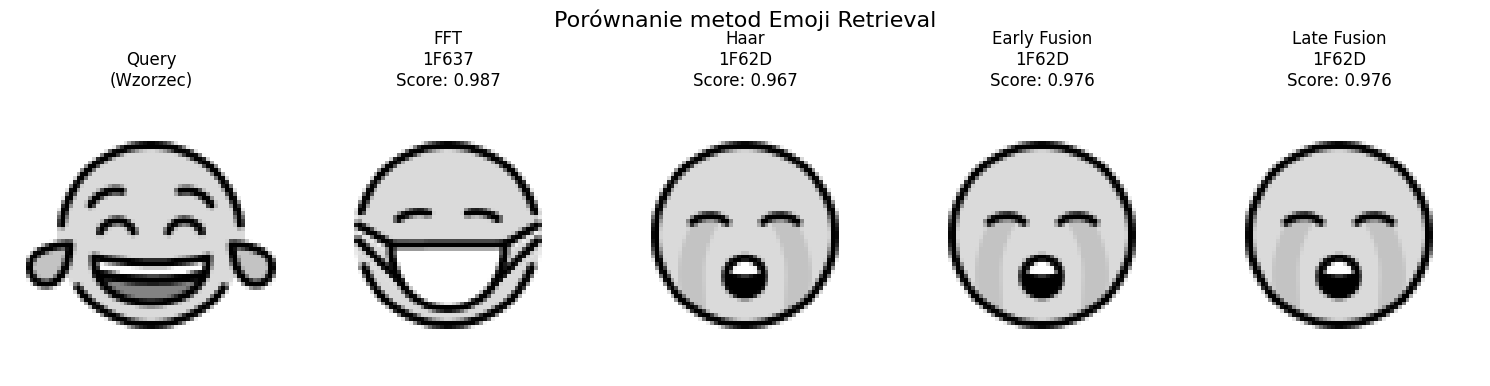

In [10]:
plt.figure(figsize=(15, 4))
plt.subplot(1, len(methods) + 1, 1)
plt.imshow(query_emoji, cmap="gray", vmin=0, vmax=1)
plt.title("Query\n(Wzorzec)")
plt.axis("off")

for idx, method in enumerate(methods):
    best_name, best_score = results[method]
    best_img = emojis[best_name]
    
    plt.subplot(1, len(methods) + 1, idx + 2)
    plt.imshow(best_img, cmap="gray", vmin=0, vmax=1)
    plt.title(f"{method}\n{best_name}\nScore: {best_score:.3f}")
    plt.axis("off")

plt.tight_layout()
plt.suptitle("Porównanie metod Emoji Retrieval", fontsize=16, y=1.05)
plt.show()

**Wnioski:**
 - `FFT` wybrało emotke z maską (inną niż inne metody) prawdopobobnie z powodu pomylenia uśmiechu z maaską oraz łez z paskami od maski. Dzieje się tak ze względu na ignorowanie lokalizacji cech przez FFT.
 - `Haar`, `Early Fusion` i `Late Fusion` wybrały tą samą emotke co metoda oparta na korelacje w lab03
 - Obie fuzje były w stanie odrzucić obiekt o innej budowie na rzecz obiektu o bardziej zbliżonej topologii twarzy.
 - `Early Fusion` i `Late Fusion` mają ten sam score (i nie jest to przypadek tylko matematyczna zależność). Stało się tak przez wybór metryki, normalizacji cech oraz równe proporcje w `Late Fusion`.